## Build a Baseline Model

In [14]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
# Phase 4 - Machine Learning
# Load datasets and initialize project paths

from pathlib import Path
import pandas as pd
import numpy as np

# Project directory
PROJECT_ROOT = Path(
    r"C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI"
)

# Data directories
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

# Verify paths
print("Project exists:", PROJECT_ROOT.exists())
print("Processed directory exists:", PROCESSED_DIR.exists())

# Load Phase 3.7 datasets
train_df = pd.read_parquet(PROCESSED_DIR / "train.parquet")
val_df = pd.read_parquet(PROCESSED_DIR / "validation.parquet")
test_df = pd.read_parquet(PROCESSED_DIR / "test.parquet")

print("\nDatasets loaded successfully!")
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Project exists: True
Processed directory exists: True

Datasets loaded successfully!
Training: (1426327, 18)
Validation: (379779, 18)
Testing: (410078, 18)


In [4]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI"
)

# Search the project for Parquet files
parquet_files = list(project_dir.rglob("*.parquet"))

print("Found Parquet files:\n")

for file in parquet_files:
    print(file)

Found Parquet files:

C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\notebooks\data\processed\test.parquet
C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\notebooks\data\processed\train.parquet
C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\notebooks\data\processed\validation.parquet
C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\data\processed\berlin_bicycle_calendar_features.parquet
C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\data\processed\berlin_bicycle_cleaned.parquet
C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\data\processed\berlin_bicycle_model_ready.parquet
C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\data\processed\berlin_bicycle_quality_flagged.parquet
C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\data\processed\berlin_bicycle_rolling_features.parquet
C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\data\processed\berlin_bicycle_station_features.parquet
C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\data\processed\berlin_traffic_all_years.p

In [4]:
# Load datasets from Phase 3.7

from pathlib import Path
import pandas as pd

# Define project directory
PROJECT_ROOT = Path(
    r"C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Define dataset paths
train_path = PROCESSED_DIR / "train.parquet"
val_path = PROCESSED_DIR / "validation.parquet"
test_path = PROCESSED_DIR / "test.parquet"

# Load datasets
train_df = pd.read_parquet(train_path)
val_df = pd.read_parquet(val_path)
test_df = pd.read_parquet(test_path)

print("All datasets loaded successfully!")

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

All datasets loaded successfully!
Training: (1426327, 18)
Validation: (379779, 18)
Testing: (410078, 18)


In [9]:
# Historical average for each station, weekday and hour
station_hour_mean = (
    train_df
    .groupby(
        ["station_id", "day_of_week", "hour"],
        observed=True
    )["bicycle_count"]
    .mean()
    .reset_index(name="station_hour_avg")
)

# Historical average by weekday and hour
calendar_mean = (
    train_df
    .groupby(["day_of_week", "hour"])["bicycle_count"]
    .mean()
    .reset_index(name="calendar_avg")
)

# Overall average
global_mean = train_df["bicycle_count"].mean()

print("Station-hour combinations:", len(station_hour_mean))
print("Global average:", round(global_mean, 2))

station_hour_mean.head()

Station-hour combinations: 5040
Global average: 87.79


,station_id,day_of_week,hour,station_hour_avg
0,01-MI-AL-W,0,0,6.6875
1,01-MI-AL-W,0,1,3.6250
2,01-MI-AL-W,0,2,2.8750
3,01-MI-AL-W,0,3,4.1875
4,01-MI-AL-W,0,4,8.3750


In [6]:
def baseline_predict(X):

    # Keep required columns
    features = X[
        ["station_id", "day_of_week", "hour"]
    ].copy()

    # Merge station-specific averages
    features = features.merge(
        station_hour_mean,
        on=["station_id", "day_of_week", "hour"],
        how="left",
        sort=False
    )

    # Merge calendar averages
    features = features.merge(
        calendar_mean,
        on=["day_of_week", "hour"],
        how="left",
        sort=False
    )

    # Apply fallback strategy
    predictions = (
        features["station_hour_avg"]
        .fillna(features["calendar_avg"])
        .fillna(global_mean)
    )

    return predictions.to_numpy()

In [10]:
feature_cols = [
    "station_id", "year", "hour", "day_of_week",
    "month", "day_of_year", "is_weekend",
    "hour_sin", "hour_cos", "dow_sin", "dow_cos",
    "month_sin", "month_cos"
]

X_train = train_df[feature_cols].copy()
y_train = train_df["bicycle_count"].copy()

X_val = val_df[feature_cols].copy()
y_val = val_df["bicycle_count"].copy()

print("Variables restored successfully!")

Variables restored successfully!


In [11]:
# Calculate historical averages from training data
station_hour_mean = (
    train_df.groupby(
        ["station_id", "day_of_week", "hour"],
        observed=True
    )["bicycle_count"]
    .mean()
    .reset_index(name="station_hour_avg")
)

calendar_mean = (
    train_df.groupby(
        ["day_of_week", "hour"]
    )["bicycle_count"]
    .mean()
    .reset_index(name="calendar_avg")
)

global_mean = train_df["bicycle_count"].mean()


# Define baseline prediction function
def baseline_predict(X):

    features = X[
        ["station_id", "day_of_week", "hour"]
    ].copy()

    features = features.merge(
        station_hour_mean,
        on=["station_id", "day_of_week", "hour"],
        how="left",
        sort=False
    )

    features = features.merge(
        calendar_mean,
        on=["day_of_week", "hour"],
        how="left",
        sort=False
    )

    predictions = (
        features["station_hour_avg"]
        .fillna(features["calendar_avg"])
        .fillna(global_mean)
    )

    return predictions.to_numpy()


print("Baseline prediction function ready!")

Baseline prediction function ready!


In [12]:
y_val_pred = baseline_predict(X_val)

print("Number of predictions:", len(y_val_pred))

comparison = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Predicted": y_val_pred
})

display(comparison.head(10))

Number of predictions: 379779


,Actual,Predicted
0,10.0,8.733333
1,24.0,50.503049
2,25.0,52.067073
3,18.0,15.634146
4,22.0,26.107034
5,56.0,77.774704
6,43.0,53.675889
7,12.0,23.966361
8,11.0,11.390244
9,10.0,34.500000


In [15]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_val, y_val_pred)

rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred)
)

r2 = r2_score(y_val, y_val_pred)

print("===== BASELINE MODEL RESULTS =====")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")

===== BASELINE MODEL RESULTS =====
MAE:  40.74
RMSE: 68.64
R²:   0.6654


In [16]:
# Identify stations available during training
known_stations = set(train_df["station_id"])

# Determine which validation stations are known
known_mask = (
    val_df["station_id"]
    .isin(known_stations)
    .to_numpy()
)

def evaluate_group(name, mask):
    if not mask.any():
        print(f"{name}: No observations")
        return

    print(f"\n{name}")
    print("Observations:", mask.sum())

    print("MAE:", round(
        mean_absolute_error(
            y_val.to_numpy()[mask],
            y_val_pred[mask]
        ), 2
    ))

    print("RMSE:", round(
        np.sqrt(mean_squared_error(
            y_val.to_numpy()[mask],
            y_val_pred[mask]
        )), 2
    ))

evaluate_group("Known stations", known_mask)

evaluate_group("Unseen stations", ~known_mask)


Known stations
Observations: 354896
MAE: 39.01
RMSE: 66.73

Unseen stations
Observations: 24883
MAE: 65.29
RMSE: 91.64


## Machine Learning Preprocessing Pipeline

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Numerical features
numerical_features = [
    "year",
    "hour",
    "day_of_week",
    "month",
    "day_of_year",
    "is_weekend",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos"
]

# Categorical features
categorical_features = ["station_id"]

# Check selected features
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

assert set(X_train.columns) == set(
    numerical_features + categorical_features
), "Training features do not match the expected 13 columns."

Numerical features: 12
Categorical features: 1


In [18]:
# Numerical preprocessing pipeline
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing pipeline
categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [19]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply learned transformations to validation data
X_val_processed = preprocessor.transform(X_val)

print("===== PREPROCESSING RESULTS =====")

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print()

print("Original validation shape:", X_val.shape)
print("Processed validation shape:", X_val_processed.shape)

print()

print("Total processed features:",
      X_train_processed.shape[1])

===== PREPROCESSING RESULTS =====
Original training shape: (1426327, 13)
Processed training shape: (1426327, 42)

Original validation shape: (379779, 13)
Processed validation shape: (379779, 42)

Total processed features: 42


In [20]:
import numpy as np
from scipy import sparse

# Check feature consistency
assert (
    X_train_processed.shape[1] ==
    X_val_processed.shape[1]
), "Feature count mismatch!"

# Count missing values in dense or sparse matrices
def count_missing(X):
    values = X.data if sparse.issparse(X) else X
    return np.isnan(values).sum()

print("===== PREPROCESSING VALIDATION =====")

print("Missing values in training:",
      count_missing(X_train_processed))

print("Missing values in validation:",
      count_missing(X_val_processed))

# Identify unseen stations
unseen_mask = ~X_val["station_id"].isin(
    X_train["station_id"]
)

print()
print("Unseen station observations:",
      unseen_mask.sum())

# Display generated feature names
feature_names = preprocessor.get_feature_names_out()

print()
print("Total feature names:", len(feature_names))
print("First 15 features:")
print(feature_names[:15])

print()
print("Preprocessing validation completed!")

===== PREPROCESSING VALIDATION =====
Missing values in training: 0
Missing values in validation: 0

Unseen station observations: 24883

Total feature names: 42
First 15 features:
['num__year' 'num__hour' 'num__day_of_week' 'num__month'
 'num__day_of_year' 'num__is_weekend' 'num__hour_sin' 'num__hour_cos'
 'num__dow_sin' 'num__dow_cos' 'num__month_sin' 'num__month_cos'
 'cat__station_id_01-MI-AL-W' 'cat__station_id_02-MI-JAN-N'
 'cat__station_id_02-MI-JAN-S']

Preprocessing validation completed!


## Train the Linear Regression model

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Reuse our preprocessing configuration
lr_preprocessor = clone(preprocessor)
lr_preprocessor.set_params(sparse_threshold=1.0)


linear_model = Pipeline(steps=[
    ("preprocessing", lr_preprocessor),
    ("model", LinearRegression())
])

# Fit using training data ONLY
linear_model.fit(X_train, y_train)

print("Linear Regression training completed!")
print("Training observations:", len(X_train))
print("Features after preprocessing:",
      len(linear_model.named_steps[
          "preprocessing"
      ].get_feature_names_out()))

Linear Regression training completed!
Training observations: 1426327
Features after preprocessing: 42


In [22]:
import numpy as np
import pandas as pd

# Predict bicycle traffic
y_val_pred_lr = linear_model.predict(X_val)

# Compare actual vs predicted
comparison_lr = pd.DataFrame({
    "Actual": np.asarray(y_val),
    "Predicted": y_val_pred_lr
})

print("Number of predictions:", len(y_val_pred_lr))
print("\nFirst 10 predictions:")
print(comparison_lr.head(10))

print("\nNegative predictions:",
      np.sum(y_val_pred_lr < 0))

Number of predictions: 379779

First 10 predictions:
   Actual   Predicted
0    10.0   54.142918
1    24.0  110.405042
2    25.0  115.867444
3    18.0   20.803397
4    22.0   43.327970
5    56.0   94.266919
6    43.0   85.592138
7    12.0   38.882993
8    11.0   31.365817
9    10.0   79.730792

Negative predictions: 32578


In [23]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

lr_mae = mean_absolute_error(y_val, y_val_pred_lr)

lr_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred_lr)
)

lr_r2 = r2_score(y_val, y_val_pred_lr)

print("===== LINEAR REGRESSION RESULTS =====")
print(f"MAE:  {lr_mae:.2f}")
print(f"RMSE: {lr_rmse:.2f}")
print(f"R²:   {lr_r2:.4f}")

print("\n===== COMPARISON WITH BASELINE =====")
print(f"Baseline MAE: {40.74:.2f} | Linear MAE: {lr_mae:.2f}")
print(f"Baseline RMSE: {68.64:.2f} | Linear RMSE: {lr_rmse:.2f}")
print(f"Baseline R²: {0.6654:.4f} | Linear R²: {lr_r2:.4f}")

print(f"\nMAE reduction: {40.74 - lr_mae:.2f}")

===== LINEAR REGRESSION RESULTS =====
MAE:  58.22
RMSE: 86.04
R²:   0.4742

===== COMPARISON WITH BASELINE =====
Baseline MAE: 40.74 | Linear MAE: 58.22
Baseline RMSE: 68.64 | Linear RMSE: 86.04
Baseline R²: 0.6654 | Linear R²: 0.4742

MAE reduction: -17.48


In [24]:
# Identify stations present during training
known_station_ids = X_train["station_id"].unique()

known_mask = X_val["station_id"].isin(
    known_station_ids
).to_numpy()

unseen_mask = ~known_mask

def evaluate_group(name, mask):
    actual = np.asarray(y_val)[mask]
    predicted = y_val_pred_lr[mask]

    print(f"\n{name}")
    print("Observations:", len(actual))
    print(f"MAE: {mean_absolute_error(actual, predicted):.2f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(actual, predicted)):.2f}")
    print(f"R²: {r2_score(actual, predicted):.4f}")

print("===== LINEAR REGRESSION BY STATION =====")

evaluate_group("Known stations", known_mask)
evaluate_group("Unseen stations", unseen_mask)

===== LINEAR REGRESSION BY STATION =====

Known stations
Observations: 354896
MAE: 57.06
RMSE: 85.35
R²: 0.4908

Unseen stations
Observations: 24883
MAE: 74.80
RMSE: 95.36
R²: -0.0429


## Train the Decision Tree model

In [25]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Reuse our preprocessing configuration
tree_preprocessor = clone(preprocessor)

# Keep processed data sparse to save memory
tree_preprocessor.set_params(sparse_threshold=1.0)

# Create Decision Tree pipeline
tree_model = Pipeline(steps=[
    ("preprocessing", tree_preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=14,
        min_samples_leaf=100,
        max_leaf_nodes=1000,
        random_state=42
    ))
])

# Train using training data ONLY
tree_model.fit(X_train, y_train)

print("Decision Tree training completed!")
print("Training observations:", len(X_train))

print("Tree depth:",
      tree_model.named_steps["model"].get_depth())

print("Number of leaves:",
      tree_model.named_steps["model"].get_n_leaves())

Decision Tree training completed!
Training observations: 1426327
Tree depth: 14
Number of leaves: 1000


In [26]:
import numpy as np
import pandas as pd

# Predict hourly bicycle counts
y_val_pred_tree = tree_model.predict(X_val)

# Compare actual vs predicted
comparison_tree = pd.DataFrame({
    "Actual": np.asarray(y_val),
    "Predicted": y_val_pred_tree
})

print("Number of predictions:", len(y_val_pred_tree))

print("\nFirst 10 predictions:")
print(comparison_tree.head(10))

print("\nNegative predictions:",
      np.sum(y_val_pred_tree < 0))

Number of predictions: 379779

First 10 predictions:
   Actual  Predicted
0    10.0   6.597748
1    24.0  24.416456
2    25.0  26.391139
3    18.0   6.597748
4    22.0  17.264493
5    56.0  66.810945
6    43.0  57.184080
7    12.0   6.597748
8    11.0   6.597748
9    10.0  17.647863

Negative predictions: 0


In [27]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

tree_mae = mean_absolute_error(y_val, y_val_pred_tree)

tree_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred_tree)
)

tree_r2 = r2_score(y_val, y_val_pred_tree)

print("===== DECISION TREE RESULTS =====")
print(f"MAE:  {tree_mae:.2f}")
print(f"RMSE: {tree_rmse:.2f}")
print(f"R²:   {tree_r2:.4f}")

# Compare all models
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Decision Tree"
    ],
    "MAE": [40.74, lr_mae, tree_mae],
    "RMSE": [68.64, lr_rmse, tree_rmse],
    "R2": [0.6654, lr_r2, tree_r2]
})

print("\n===== MODEL COMPARISON =====")
print(results.round(4).to_string(index=False))

print("\nDecision Tree improvement over baseline:")
print(f"MAE improvement: {40.74 - tree_mae:.2f}")
print(f"RMSE improvement: {68.64 - tree_rmse:.2f}")

===== DECISION TREE RESULTS =====
MAE:  43.30
RMSE: 74.33
R²:   0.6076

===== MODEL COMPARISON =====
            Model     MAE    RMSE     R2
         Baseline 40.7400 68.6400 0.6654
Linear Regression 58.2233 86.0415 0.4742
    Decision Tree 43.3036 74.3305 0.6076

Decision Tree improvement over baseline:
MAE improvement: -2.56
RMSE improvement: -5.69


In [28]:
known_stations = X_train["station_id"].unique()

known_mask = X_val["station_id"].isin(
    known_stations
).to_numpy()

unseen_mask = ~known_mask

def evaluate_tree_group(name, mask):
    actual = np.asarray(y_val)[mask]
    predicted = y_val_pred_tree[mask]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    print(f"\n{name}")
    print("Observations:", len(actual))
    print(f"MAE: {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R²: {r2:.4f}")

print("===== DECISION TREE BY STATION =====")

evaluate_tree_group("Known stations", known_mask)
evaluate_tree_group("Unseen stations", unseen_mask)

===== DECISION TREE BY STATION =====

Known stations
Observations: 354896
MAE: 42.81
RMSE: 73.85
R²: 0.6188

Unseen stations
Observations: 24883
MAE: 50.34
RMSE: 80.90
R²: 0.2494


In [54]:
# Predict training data
y_train_pred_tree = tree_model.predict(X_train)

train_mae = mean_absolute_error(
    y_train, y_train_pred_tree
)

train_r2 = r2_score(
    y_train, y_train_pred_tree
)

print("===== OVERFITTING CHECK =====")

print(f"Training MAE:   {train_mae:.2f}")
print(f"Validation MAE: {tree_mae:.2f}")

print(f"\nTraining R²:   {train_r2:.4f}")
print(f"Validation R²: {tree_r2:.4f}")

print(f"\nMAE gap: {tree_mae - train_mae:.2f}")

===== OVERFITTING CHECK =====
Training MAE:   35.80
Validation MAE: 43.30

Training R²:   0.7254
Validation R²: 0.6076

MAE gap: 7.50


## Train the Random Forest

In [55]:
print(X_train.dtypes.value_counts())

print("\nText columns:")
print(X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist())

float64    6
int32      5
string     1
int64      1
Name: count, dtype: int64

Text columns:
['station_id']


In [56]:
# Remove raw station_id if it is still present
X_train_rf = X_train.drop(columns=["station_id"], errors="ignore")
X_val_rf = X_val.drop(columns=["station_id"], errors="ignore")

# Verify numerical features
print("Training shape:", X_train_rf.shape)
print("Validation shape:", X_val_rf.shape)

print("\nNon-numeric columns:")
print(X_train_rf.select_dtypes(
    exclude=["number", "bool"]
).columns.tolist())

Training shape: (1426327, 12)
Validation shape: (379779, 12)

Non-numeric columns:
[]


In [57]:
# Inspect Random Forest features
print("Number of features:", X_train_rf.shape[1])

print("\nFeatures:")
print(X_train_rf.columns.tolist())

# Count encoded station columns
station_features = [
    col for col in X_train_rf.columns
    if col.startswith("station_")
]

print("\nNumber of station features:", len(station_features))

# Check prediction diversity
print("\nUnique predictions:",
      len(np.unique(y_val_pred_rf)))

print("\nPrediction standard deviation:",
      np.std(y_val_pred_rf))

Number of features: 12

Features:
['year', 'hour', 'day_of_week', 'month', 'day_of_year', 'is_weekend', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos']

Number of station features: 0

Unique predictions: 94803

Prediction standard deviation: 93.64173829350176


In [58]:
import pandas as pd

# Create one-hot encoded features
X_train_rf = pd.get_dummies(
    X_train,
    columns=["station_id"],
    dtype=int
)

X_val_rf = pd.get_dummies(
    X_val,
    columns=["station_id"],
    dtype=int
)

# Match validation columns to training columns
X_val_rf = X_val_rf.reindex(
    columns=X_train_rf.columns,
    fill_value=0
)

print("Training shape:", X_train_rf.shape)
print("Validation shape:", X_val_rf.shape)

print("Missing values:", X_train_rf.isna().sum().sum())
print("Station features:",
      len([c for c in X_train_rf.columns
           if c.startswith("station_id_")]))

Training shape: (1426327, 42)
Validation shape: (379779, 42)
Missing values: 0
Station features: 30


In [41]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=60,
    max_depth=18,
    min_samples_leaf=10,
    max_features=0.8,
    max_samples=0.7,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_rf, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [42]:

y_val_pred_rf = rf_model.predict(X_val_rf)

print("Number of predictions:", len(y_val_pred_rf))

print(pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Predicted": y_val_pred_rf
}).head(10))

Number of predictions: 379779
   Actual  Predicted
0    10.0   4.683039
1    24.0  37.747659
2    25.0  35.872580
3    18.0   7.154507
4    22.0  19.798258
5    56.0  72.795656
6    43.0  47.648228
7    12.0  20.388459
8    11.0   4.683039
9    10.0  19.201468


In [52]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_mae = mean_absolute_error(y_val, y_val_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred_rf))
rf_r2 = r2_score(y_val, y_val_pred_rf)

print("===== CORRECTED RANDOM FOREST RESULTS =====")
print(f"MAE:  {rf_mae:.2f}")
print(f"RMSE: {rf_rmse:.2f}")
print(f"R²:   {rf_r2:.4f}")

===== CORRECTED RANDOM FOREST RESULTS =====
MAE:  35.95
RMSE: 64.17
R²:   0.7075


##  Gradient Boosting Regression

In [59]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

# Reuse the corrected station-aware features
X_train_gb = X_train_rf
X_val_gb = X_val_rf

# Verify the features
station_features = [
    col for col in X_train_gb.columns
    if col.startswith("station_id_")
]

print("Training shape:", X_train_gb.shape)
print("Validation shape:", X_val_gb.shape)
print("Station features:", len(station_features))

assert X_train_gb.columns.equals(X_val_gb.columns)
assert len(station_features) > 0, "Station features are missing!"

# Initialize Gradient Boosting
gb_model = HistGradientBoostingRegressor(
    learning_rate=0.07,
    max_iter=200,
    max_leaf_nodes=31,
    min_samples_leaf=50,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=42
)

# Train the model
start_time = time.time()

gb_model.fit(X_train_gb, y_train)

training_time = time.time() - start_time

print("\nGradient Boosting training completed!")
print(f"Training time: {training_time:.2f} seconds")
print("Iterations used:", gb_model.n_iter_)

Training shape: (1426327, 42)
Validation shape: (379779, 42)
Station features: 30



Gradient Boosting training completed!
Training time: 135.04 seconds
Iterations used: 200


In [60]:
# Generate predictions
y_pred_gb = gb_model.predict(X_val_gb)

# Traffic counts cannot be negative
y_pred_gb = np.maximum(y_pred_gb, 0)

# Calculate evaluation metrics
gb_mae = mean_absolute_error(y_val, y_pred_gb)
gb_rmse = np.sqrt(mean_squared_error(y_val, y_pred_gb))
gb_r2 = r2_score(y_val, y_pred_gb)

print("===== GRADIENT BOOSTING RESULTS =====")
print(f"MAE:  {gb_mae:.2f}")
print(f"RMSE: {gb_rmse:.2f}")
print(f"R²:   {gb_r2:.4f}")

print("\nNumber of predictions:", len(y_pred_gb))

# Compare actual and predicted values
import pandas as pd

comparison_gb = pd.DataFrame({
    "Actual": np.asarray(y_val),
    "Predicted": y_pred_gb
})

print("\nFirst 10 predictions:")
print(comparison_gb.head(10))

===== GRADIENT BOOSTING RESULTS =====
MAE:  30.94
RMSE: 53.03
R²:   0.8003

Number of predictions: 379779

First 10 predictions:
   Actual  Predicted
0    10.0  10.235149
1    24.0  33.262140
2    25.0  27.750473
3    18.0  10.412632
4    22.0   9.001115
5    56.0  94.152195
6    43.0  67.660716
7    12.0  15.775637
8    11.0   6.936173
9    10.0  15.374167


In [61]:
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        40.74,
        58.22,
        43.30,
        35.95,
        gb_mae
    ],
    "RMSE": [
        68.64,
        86.04,
        74.33,
        64.17,
        gb_rmse
    ],
    "R2": [
        0.6654,
        0.4742,
        0.6076,
        0.7075,
        gb_r2
    ]
})

# Sort by lowest MAE
model_comparison = model_comparison.sort_values("MAE")

print("===== FINAL MODEL COMPARISON =====")
print(model_comparison.to_string(index=False))

===== FINAL MODEL COMPARISON =====
            Model       MAE      RMSE       R2
Gradient Boosting 30.938793 53.030999 0.800253
    Random Forest 35.950000 64.170000 0.707500
         Baseline 40.740000 68.640000 0.665400
    Decision Tree 43.300000 74.330000 0.607600
Linear Regression 58.220000 86.040000 0.474200


## Final Test Set Evaluation

In [63]:

from pathlib import Path
import pandas as pd

# Find the project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Load the untouched test dataset
test_path = project_root / "data" / "processed" / "test.parquet"

test_df = pd.read_parquet(test_path)

print("Test dataset shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())


Test dataset shape: (410078, 18)
Columns: ['timestamp', 'station_id', 'bicycle_count', 'year', 'extreme_threshold', 'extreme_flag', 'hour', 'day_of_week', 'month', 'day_of_year', 'is_weekend', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'time_difference']


In [64]:

# Separate features and target
target = "bicycle_count"

X_test = test_df.drop(columns=[target])
y_test = test_df[target]

# Use exactly the same raw features as training
X_test = X_test[X_train_gb.columns] if "station_id" in X_train_gb.columns else X_test[
    ["station_id", "year", "hour", "day_of_week",
     "month", "day_of_year", "is_weekend",
     "hour_sin", "hour_cos", "dow_sin", "dow_cos",
     "month_sin", "month_cos"]
]

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


X_test shape: (410078, 13)
y_test shape: (410078,)


In [65]:

# Apply the same encoding as Gradient Boosting training
X_test_gb = pd.get_dummies(
    X_test.copy(),
    columns=["station_id"]
)

# Match the exact training feature columns
X_test_gb = X_test_gb.reindex(
    columns=X_train_gb.columns,
    fill_value=0
)

print("Test features:", X_test_gb.shape[1])
print("Test observations:", len(X_test_gb))
print("Missing values:", X_test_gb.isna().sum().sum())


Test features: 42
Test observations: 410078
Missing values: 0


In [66]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict on the untouched test dataset
y_test_pred_gb = gb_model.predict(X_test_gb)

# Calculate evaluation metrics
test_mae = mean_absolute_error(y_test, y_test_pred_gb)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_gb))
test_r2 = r2_score(y_test, y_test_pred_gb)

print("===== FINAL GRADIENT BOOSTING TEST RESULTS =====")
print(f"MAE:  {test_mae:.2f}")
print(f"RMSE: {test_rmse:.2f}")
print(f"R²:   {test_r2:.4f}")


===== FINAL GRADIENT BOOSTING TEST RESULTS =====
MAE:  33.24
RMSE: 57.95
R²:   0.7295


## Error Analysis

In [67]:
# PREDICTION ERROR ANALYSIS


import pandas as pd
import numpy as np

# Generate predictions using our final model
y_test_pred = gb_model.predict(X_test_gb)

# Create error analysis DataFrame
error_df = pd.DataFrame({
    "Actual": np.asarray(y_test),
    "Predicted": y_test_pred
})

# Calculate errors
error_df["Error"] = (
    error_df["Actual"] - error_df["Predicted"]
)

error_df["Absolute_Error"] = error_df["Error"].abs()

error_df["Squared_Error"] = error_df["Error"] ** 2

# Display results
print("Total observations:", len(error_df))
print(error_df.head(10))


Total observations: 410078
   Actual   Predicted       Error  Absolute_Error  Squared_Error
0    65.0   27.189041   37.810959       37.810959    1429.668613
1   123.0   53.727220   69.272780       69.272780    4798.718109
2    10.0   53.705434  -43.705434       43.705434    1910.164940
3    43.0   28.594421   14.405579       14.405579     207.520698
4    79.0   24.609356   54.390644       54.390644    2958.342129
5    18.0   27.189041   -9.189041        9.189041      84.438476
6   266.0  125.725615  140.274385      140.274385   19676.902977
7   154.0   83.594624   70.405376       70.405376    4956.916926
8    96.0   33.150308   62.849692       62.849692    3950.083724
9    41.0   20.916675   20.083325       20.083325     403.339953


In [ ]:

# ERROR STATISTICS


print("===== ERROR ANALYSIS SUMMARY =====")

print(
    "Mean Error:",
    round(error_df["Error"].mean(), 2)
)

print(
    "Mean Absolute Error:",
    round(error_df["Absolute_Error"].mean(), 2)
)

print(
    "Median Absolute Error:",
    round(error_df["Absolute_Error"].median(), 2)
)

print(
    "90th Percentile Absolute Error:",
    round(error_df["Absolute_Error"].quantile(0.90), 2)
)

print(
    "Maximum Absolute Error:",
    round(error_df["Absolute_Error"].max(), 2)
)


===== ERROR ANALYSIS SUMMARY =====
Mean Error: -0.11
Mean Absolute Error: 33.24
Median Absolute Error: 15.69
90th Percentile Absolute Error: 87.8
Maximum Absolute Error: 3113.82


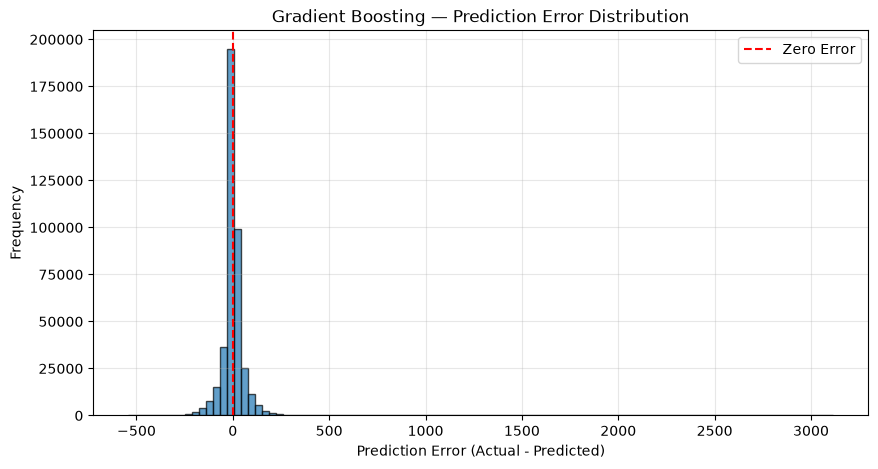

In [69]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    error_df["Error"],
    bins=100,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.title("Gradient Boosting — Prediction Error Distribution")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [70]:

# HOURLY ERROR ANALYSIS

# Add hour information from the test dataset
error_df["hour"] = X_test["hour"].to_numpy()

# Calculate error statistics by hour
hourly_errors = (
    error_df.groupby("hour")
    .agg(
        MAE=("Absolute_Error", "mean"),
        Mean_Error=("Error", "mean"),
        Observations=("Error", "count")
    )
    .reset_index()
)

print("===== HOURLY ERROR ANALYSIS =====")
print(hourly_errors.round(2))


===== HOURLY ERROR ANALYSIS =====
    hour    MAE  Mean_Error  Observations
0      0  11.03        0.53         17088
1      1   7.51        1.41         17088
2      2   6.19        1.42         17053
3      3   5.57       -0.54         17087
4      4   6.05        0.84         17086
5      5   9.27        4.26         17087
6      6  14.59        1.05         17087
7      7  43.38       -3.51         17087
8      8  66.87       -0.06         17087
9      9  50.74       -4.05         17087
10    10  32.61       -3.27         17087
11    11  33.24       -4.32         17088
12    12  38.18        0.96         17088
13    13  41.38       -1.43         17088
14    14  44.00       -2.30         17089
15    15  53.90       -3.62         17089
16    16  55.60       -2.26         17089
17    17  62.74        4.71         17089
18    18  64.37       -0.79         17089
19    19  48.65       -3.16         17089
20    20  34.36        2.56         17089
21    21  26.56        5.47         17089


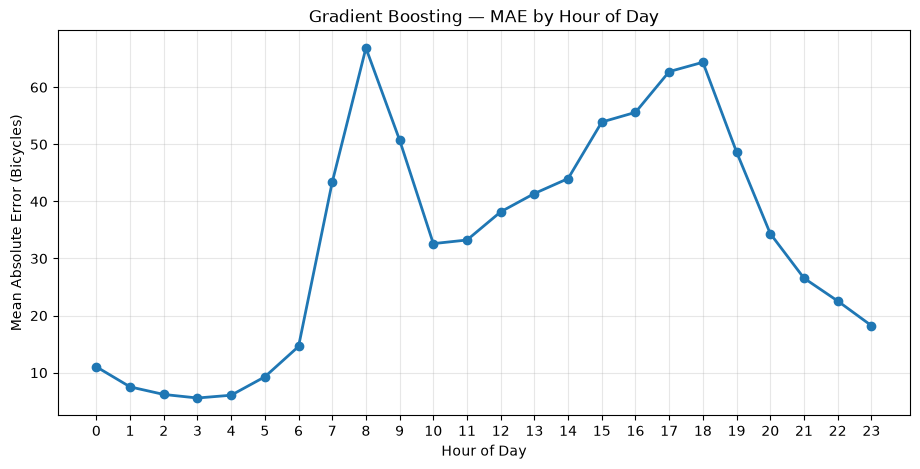

In [71]:

plt.figure(figsize=(11, 5))

plt.plot(
    hourly_errors["hour"],
    hourly_errors["MAE"],
    marker="o",
    linewidth=2
)

plt.title("Gradient Boosting — MAE by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Absolute Error (Bicycles)")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.show()


In [72]:
#  STATION-LEVEL ERROR ANALYSIS

# Add original station identities
error_df["station_id"] = X_test["station_id"].to_numpy()

# Calculate error metrics for each station
station_errors = (
    error_df.groupby("station_id")
    .agg(
        MAE=("Absolute_Error", "mean"),
        Mean_Error=("Error", "mean"),
        RMSE=("Squared_Error", lambda x: np.sqrt(x.mean())),
        Observations=("Error", "count")
    )
    .reset_index()
)

# Sort from highest to lowest MAE
station_errors = station_errors.sort_values(
    by="MAE",
    ascending=False
)

print("===== STATION-LEVEL ERROR ANALYSIS =====")
print(station_errors.round(2).to_string(index=False))


===== STATION-LEVEL ERROR ANALYSIS =====
 station_id   MAE  Mean_Error   RMSE  Observations
 09-PA-SA-S 68.72       65.96 101.77         11855
 16-SP-NO-O 63.74      -61.76  84.47         11855
 16-SP-NO-W 63.17      -62.53  83.51         11855
   07-FK-ST 63.02       47.90 107.20         11855
05-FK-OBB-O 57.71       26.12  80.83         11831
02-MI-JAN-S 57.41      -39.00  95.46         11457
   04-MI-NO 55.85      -54.02  82.66          9879
05-FK-OBB-W 54.38       29.64  77.93         11855
  12-PA-SCH 50.65      -12.73  80.80         11855
 01-MI-AL-W 43.36       30.29  82.04         11855
  19-TS-MON 39.41      -20.48  70.62          9628
 11-PA-SE-N 38.73       -3.29  58.75         11855
  21-NK-MAY 37.40       -9.06  54.63         11855
02-MI-JAN-N 33.43      -12.22  53.52         11855
10-PA-BER-N 32.50        7.15  51.46         11855
  26-LI-PUP 31.44      -15.33  48.25         11855
10-PA-BER-S 30.04        7.76  48.85         11855
18-TS-YOR-O 27.69       11.40  44.06     

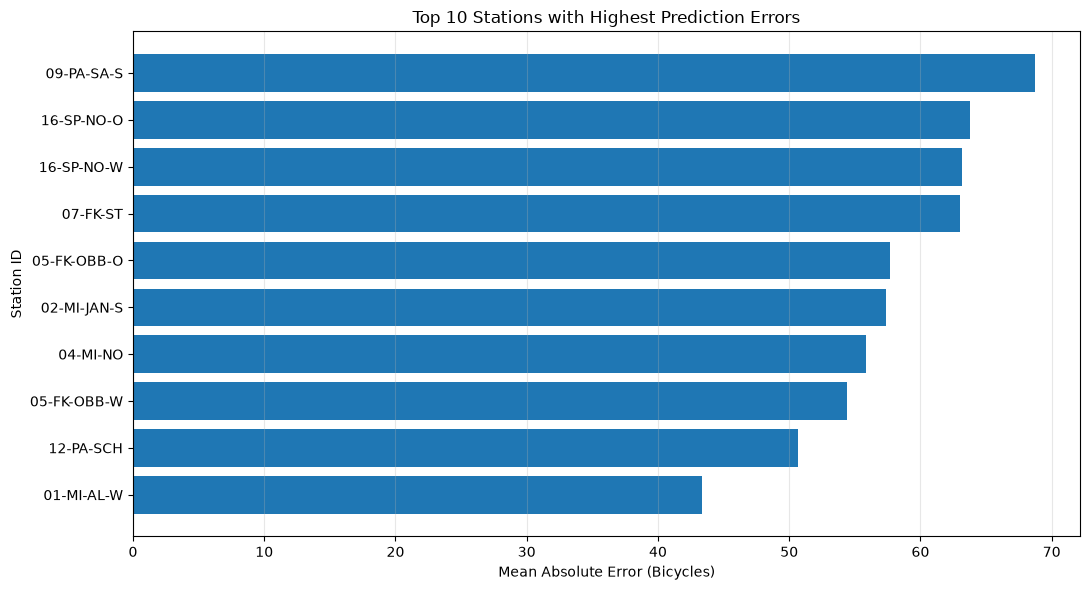

In [73]:

# Select 10 stations with highest MAE
top_10 = station_errors.head(10)

plt.figure(figsize=(11, 6))

plt.barh(
    top_10["station_id"],
    top_10["MAE"]
)

plt.xlabel("Mean Absolute Error (Bicycles)")
plt.ylabel("Station ID")
plt.title("Top 10 Stations with Highest Prediction Errors")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


In [74]:

# PEAK-HOUR ERROR ANALYSIS


import numpy as np
import pandas as pd

# Categorize observations by time of day
conditions = [
    error_df["hour"].between(7, 9),
    error_df["hour"].between(16, 18)
]

choices = ["Morning Peak", "Evening Peak"]

error_df["Traffic_Period"] = np.select(
    conditions,
    choices,
    default="Off-Peak"
)

# Calculate performance for each period
peak_errors = (
    error_df.groupby("Traffic_Period")
    .agg(
        MAE=("Absolute_Error", "mean"),
        Mean_Error=("Error", "mean"),
        RMSE=("Squared_Error", lambda x: np.sqrt(x.mean())),
        Observations=("Error", "count")
    )
    .reset_index()
)

print("===== PEAK-HOUR ERROR ANALYSIS =====")
print(peak_errors.round(2).to_string(index=False))


===== PEAK-HOUR ERROR ANALYSIS =====
Traffic_Period   MAE  Mean_Error  RMSE  Observations
  Evening Peak 60.90        0.55 90.31         51267
  Morning Peak 53.66       -2.54 86.10         51261
      Off-Peak 25.22        0.18 43.39        307550


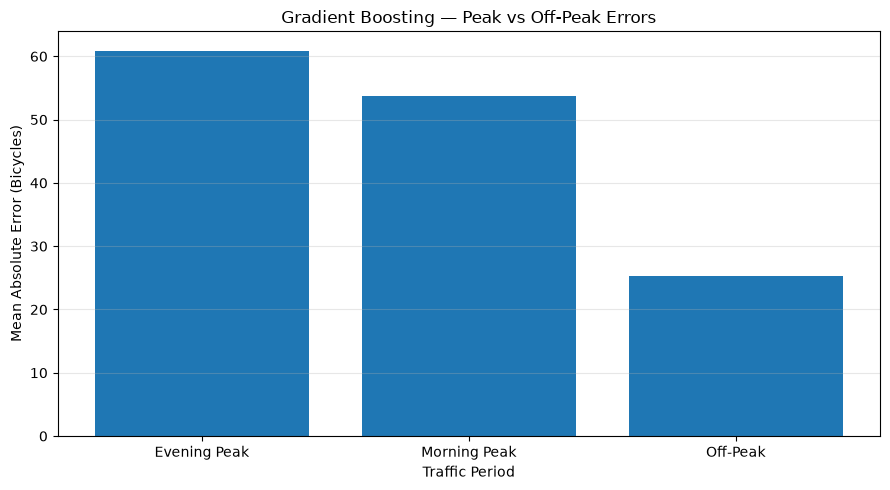

In [75]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    peak_errors["Traffic_Period"],
    peak_errors["MAE"]
)

plt.title("Gradient Boosting — Peak vs Off-Peak Errors")
plt.xlabel("Traffic Period")
plt.ylabel("Mean Absolute Error (Bicycles)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [76]:
import numpy as np

# Recover the station IDs represented in the model's training features
prefix = "station_id_"
known_station_ids = {
    column[len(prefix):]
    for column in X_train_gb.columns
    if column.startswith(prefix)
}

if not known_station_ids:
    raise ValueError("X_train_gb is missing the station one-hot columns.")

error_df["Station_Status"] = np.where(
    error_df["station_id"].isin(known_station_ids),
    "Known",
    "Unseen"
)

station_group_errors = (
    error_df.groupby("Station_Status")
    .agg(
        Stations=("station_id", "nunique"),
        Observations=("Error", "size"),
        MAE=("Absolute_Error", "mean"),
        RMSE=("Squared_Error", lambda errors: np.sqrt(errors.mean())),
        Mean_Error=("Error", "mean"),
        Mean_Actual=("Actual", "mean")
    )
)

# Compare total absolute error relative to actual traffic volume
station_group_errors["WAPE_pct"] = (
    100 * station_group_errors["MAE"]
    / station_group_errors["Mean_Actual"].replace(0, np.nan)
)

print(station_group_errors.round(2).to_string())

unseen_stations = sorted(
    error_df.loc[error_df["Station_Status"].eq("Unseen"), "station_id"].unique()
)
print("\nUnseen stations:", ", ".join(unseen_stations) or "None")

                Stations  Observations    MAE   RMSE  Mean_Error  Mean_Actual  WAPE_pct
Station_Status                                                                         
Known                 30        352779  28.38  50.04        1.73        95.37     29.76
Unseen                 5         57299  63.14  92.84      -11.47        69.75     90.52

Unseen stations: 04-MI-NO, 07-FK-ST, 09-PA-SA-S, 16-SP-NO-O, 16-SP-NO-W


## Feature Importance

In [77]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

rng = np.random.default_rng(42)

# Use a reproducible validation sample for a quick first pass.
sample_rows = rng.choice(
    len(X_val_gb), size=min(20_000, len(X_val_gb)), replace=False
)
X_sample = X_val_gb.iloc[sample_rows].reset_index(drop=True)
y_sample = np.asarray(y_val)[sample_rows]

feature_groups = {
    "Station identity": [
        col for col in X_sample.columns if col.startswith("station_id_")
    ],
    "Hour of day": ["hour", "hour_sin", "hour_cos"],
    "Day of week": ["day_of_week", "is_weekend", "dow_sin", "dow_cos"],
    "Season": ["month", "day_of_year", "month_sin", "month_cos"],
    "Year": ["year"],
}

baseline_mae = mean_absolute_error(y_sample, gb_model.predict(X_sample))
results = []

for group, columns in feature_groups.items():
    mae_increases = []

    for _ in range(3):
        order = rng.permutation(len(X_sample))
        X_shuffled = X_sample.copy()
        X_shuffled[columns] = (
            X_sample[columns].iloc[order].reset_index(drop=True)
        )

        shuffled_mae = mean_absolute_error(
            y_sample, gb_model.predict(X_shuffled)
        )
        mae_increases.append(shuffled_mae - baseline_mae)

    results.append({
        "Feature_Group": group,
        "MAE_Increase": np.mean(mae_increases),
    })

feature_importance = (
    pd.DataFrame(results)
    .sort_values("MAE_Increase", ascending=False)
    .reset_index(drop=True)
)

print(f"Validation sample MAE: {baseline_mae:.2f}")
print(feature_importance.round(2).to_string(index=False))

Validation sample MAE: 31.38
   Feature_Group  MAE_Increase
     Hour of day         58.35
Station identity         37.92
          Season         12.52
     Day of week         11.51
            Year          0.00


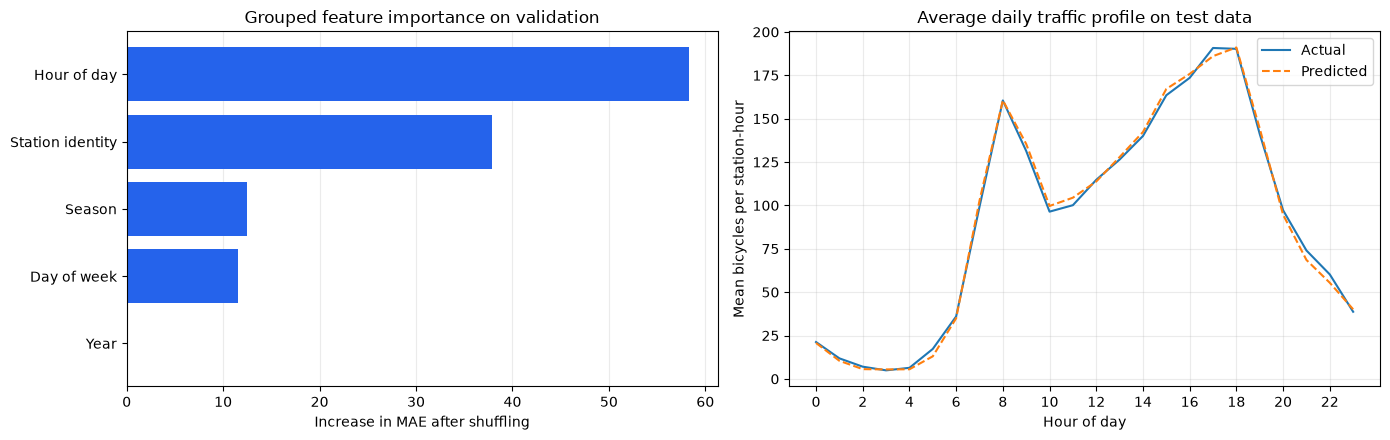

In [78]:
import matplotlib.pyplot as plt

# Use the test predictions and hour labels from Phase 5.2.
hourly_traffic = error_df.groupby("hour")[["Actual", "Predicted"]].mean()
importance_plot = feature_importance.sort_values("MAE_Increase")

fig, (ax_importance, ax_traffic) = plt.subplots(1, 2, figsize=(14, 4.5))

ax_importance.barh(
    importance_plot["Feature_Group"],
    importance_plot["MAE_Increase"],
    color="#2563EB"
)
ax_importance.set_title("Grouped feature importance on validation")
ax_importance.set_xlabel("Increase in MAE after shuffling")
ax_importance.grid(axis="x", alpha=0.25)
ax_importance.set_axisbelow(True)

ax_traffic.plot(hourly_traffic.index, hourly_traffic["Actual"], label="Actual")
ax_traffic.plot(
    hourly_traffic.index,
    hourly_traffic["Predicted"],
    linestyle="--",
    label="Predicted"
)
ax_traffic.set_title("Average daily traffic profile on test data")
ax_traffic.set_xlabel("Hour of day")
ax_traffic.set_ylabel("Mean bicycles per station-hour")
ax_traffic.set_xticks(range(0, 24, 2))
ax_traffic.grid(alpha=0.25)
ax_traffic.legend()

fig.tight_layout()
plt.show()

In [79]:
from importlib.metadata import version
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

# Find the project root from the notebook's working directory.
cwd = Path.cwd()
project_root = next(
    (folder for folder in (cwd, *cwd.parents)
     if (folder / "data" / "processed" / "test.parquet").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Run this notebook from inside the Berlin Mobility AI project."
    )

model_path = project_root / "models" / "gradient_boosting.joblib"
model_path.parent.mkdir(parents=True, exist_ok=True)

bundle = {
    "model": gb_model,
    "raw_features": X_train.columns.tolist(),
    "encoded_features": X_train_gb.columns.tolist(),
    "package_versions": {
        name: version(name)
        for name in ("scikit-learn", "numpy", "scipy", "pandas", "joblib")
    },
}
joblib.dump(bundle, model_path, compress=3)

# Reload and reproduce the same preprocessing the app will use.
saved = joblib.load(model_path)
raw_sample = X_test.loc[:, saved["raw_features"]].head(100)
encoded_sample = pd.get_dummies(raw_sample, columns=["station_id"])
encoded_sample = encoded_sample.reindex(
    columns=saved["encoded_features"], fill_value=0
)

reloaded_predictions = saved["model"].predict(encoded_sample)
np.testing.assert_allclose(
    reloaded_predictions,
    np.asarray(y_test_pred_gb)[:len(raw_sample)],
    rtol=0,
    atol=1e-10,
)

print(f"Saved model: {model_path}")
print(f"Verified predictions on {len(raw_sample)} test rows.")

Saved model: c:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\models\gradient_boosting.joblib
Verified predictions on 100 test rows.
